<a href="https://colab.research.google.com/github/mloulaps-rgb/---/blob/main/HCI_%D0%9B%D0%A03_%D0%92%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BD%D1%96_%D0%BF%D1%80%D0%B5%D0%B4%D1%81%D1%82%D0%B0%D0%B2%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D1%81%D0%BB%D1%96%D0%B2_%D0%92%D0%B5%D0%BB%D0%B8%D1%87%D0%BA%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Встановлення бібліотеки gensim (у Colab може бути відсутня)
!pip install -q gensim

# Лабораторна робота №3. Дослідження векторних представлень слів (word2vec).
# Крок 1-2. Завантаження тестового словника та моделі векторних представлень
#           слів української мови (ubercorpus word2vec, 300 вимірів).
import numpy as np
import gensim
from gensim.models import KeyedVectors

# тестовий набір аналогій "столиця - країна"
!wget -q -O test_vocabulary.txt https://raw.githubusercontent.com/lang-uk/vecs/refs/heads/master/test/test_vocabulary.txt
# векторні представлення слів (стиснений word2vec у текстовому форматі)
!wget -q -O ubercorpus.word2vec.300d.bz2 https://lang.org.ua/static/downloads/models/ubercorpus.cased.tokenized.word2vec.300d.bz2

print("Файли завантажено.")
!ls -lh test_vocabulary.txt ubercorpus.word2vec.300d.bz2

Файли завантажено.
-rw-r--r-- 1 root root 1.6M Nov 15 20:24 test_vocabulary.txt
-rw-r--r-- 1 root root 530M Feb  7  2019 ubercorpus.word2vec.300d.bz2


In [3]:
# Крок 2 (продовження). Завантаження векторів у пам'ять.
# limit обмежує словник найчастотнішими словами (економія часу й пам'яті).
word_vectors = KeyedVectors.load_word2vec_format(
    "ubercorpus.word2vec.300d.bz2", binary=False, limit=100000
)
print("Кількість слів у словнику:", len(word_vectors.index_to_key))
print("Розмірність вектора:", word_vectors.vector_size)

# приклад: вектор слова "Київ"
print("\\nВектор слова 'Київ' (перші 8 значень):")
print(np.round(word_vectors["Київ"][:8], 4))

Кількість слів у словнику: 100000
Розмірність вектора: 300
\nВектор слова 'Київ' (перші 8 значень):
[ 0.5113  0.8893  0.8115 -0.8898 -0.311  -0.9047  0.3622 -1.737 ]


In [4]:
# Крок 3. Функції косинусної подібності та евклідової відстані між векторами.
def cosine_similarity(a, b):
    """Косинусна подібність двох векторів: від -1 до 1."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

def euclidean_distance(a, b):
    """Евклідова відстань між двома векторами."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return float(np.linalg.norm(a - b))

# Демонстрація на кількох парах слів
pairs = [("Київ", "Україна"), ("Париж", "Франція"),
         ("Київ", "Париж"), ("кіт", "собака"), ("кіт", "комп'ютер")]
for w1, w2 in pairs:
    if w1 in word_vectors and w2 in word_vectors:
        cs = cosine_similarity(word_vectors[w1], word_vectors[w2])
        ed = euclidean_distance(word_vectors[w1], word_vectors[w2])
        print(f"{w1:10} <-> {w2:10}  косинус = {cs:.4f}   евклід = {ed:.3f}")

Київ       <-> Україна     косинус = 0.3799   евклід = 27.829
Париж      <-> Франція     косинус = 0.4704   евклід = 19.428
Київ       <-> Париж       косинус = 0.5536   евклід = 18.550
кіт        <-> собака      косинус = 0.7075   евклід = 15.437
кіт        <-> комп'ютер   косинус = 0.3786   евклід = 23.414


In [6]:
# Крок 4. Пошук країни за аналогією: країна_1 - столиця_1 + столиця_2 ≈ країна_2.
# Для швидкого пошуку по всьому словнику використовуємо матрицю нормованих
# векторів (скалярний добуток нормованих векторів = косинусна подібність).
norm_matrix = word_vectors.get_normed_vectors()
index_to_key = word_vectors.index_to_key

def get_country(city1, country1, city2, embeddings):
    """Повертає слово (країну), найближче за косинусною подібністю
    до вектора country1 - city1 + city2."""
    group = {city1, country1, city2}
    vec = embeddings[country1] - embeddings[city1] + embeddings[city2]
    vec = vec / np.linalg.norm(vec)
    sims = norm_matrix @ vec            # косинусна подібність до всіх слів
    for idx in np.argsort(-sims):
        word = index_to_key[idx]
        if word in group or not word.isalpha():
            continue
        return word, float(sims[idx])
    return None, -1.0

# Перевірка на класичних прикладах
for c1, co1, c2 in [("Київ", "Україна", "Париж"), ("Київ", "Україна", "Берлін"),
                    ("Київ", "Україна", "Рим"), ("Київ", "Україна", "Варшава")]:
    w, s = get_country(c1, co1, c2, word_vectors)
    print(f"{co1} - {c1} + {c2}  ->  {w}  (косинус = {s:.4f})")

Україна - Київ + Париж  ->  Європа  (косинус = 0.6416)
Україна - Київ + Берлін  ->  Європа  (косинус = 0.6891)
Україна - Київ + Рим  ->  Греція  (косинус = 0.6695)
Україна - Київ + Варшава  ->  Європа  (косинус = 0.6761)


In [7]:
# Крок 5. Тестування на всьому наборі "столиця-країна" та підрахунок точності.
def load_analogies(path):
    """Зчитує рядки виду: столиця_1 країна_1 столиця_2 країна_2."""
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith(":"):
                continue
            parts = line.split()
            if len(parts) == 4:
                rows.append(parts)
    return rows

analogies = load_analogies("test_vocabulary.txt")
print("Усього рядків аналогій у файлі:", len(analogies))

def test_accuracy(analogies, embeddings):
    correct = 0
    total = 0
    for city1, country1, city2, country2 in analogies:
        # перевіряємо, що всі слова є у словнику
        if not all(w in embeddings for w in (city1, country1, city2, country2)):
            continue
        total += 1
        pred, _ = get_country(city1, country1, city2, embeddings)
        if pred == country2:
            correct += 1
    acc = correct / total if total else 0.0
    return acc, correct, total

accuracy, correct, total = test_accuracy(analogies, word_vectors)
print(f"Перевірено пар (усі слова у словнику): {total}")
print(f"Правильно знайдено країн: {correct}")
print(f"Точність (accuracy): {accuracy:.4f} ({accuracy*100:.2f}%)")

Усього рядків аналогій у файлі: 23970
Перевірено пар (усі слова у словнику): 8122
Правильно знайдено країн: 2914
Точність (accuracy): 0.3588 (35.88%)


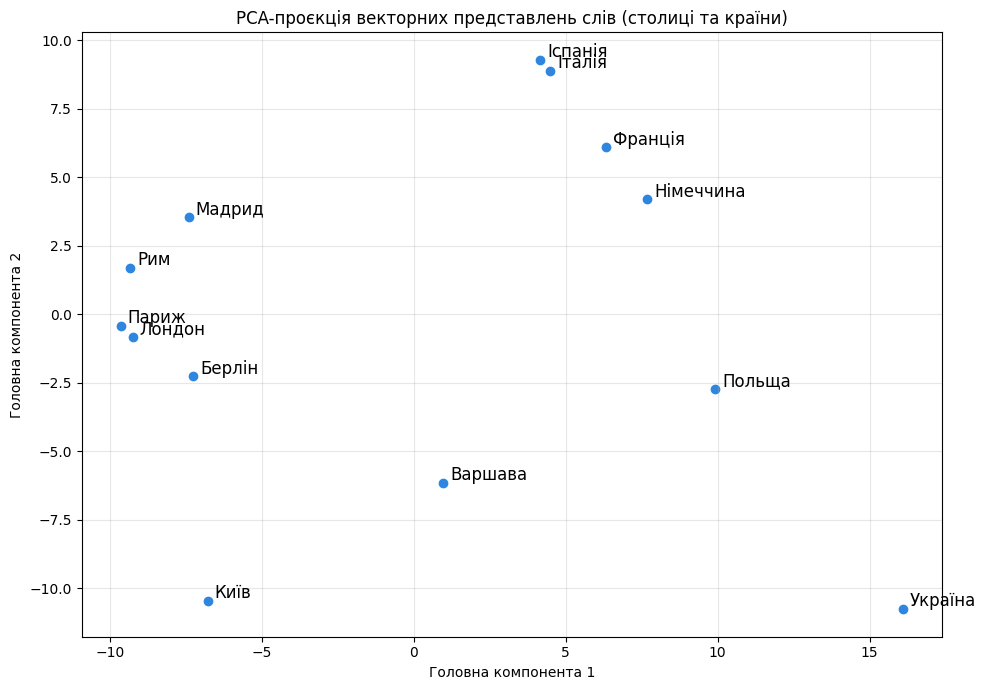

In [8]:
# Крок 6. Візуалізація векторів кількох слів на площині за допомогою PCA.
import matplotlib.pyplot as plt

def pca_2d(X, n_components=2):
    """Проєкція на головні компоненти (PCA) вручну через SVD."""
    X = np.asarray(X, dtype=float)
    X_centered = X - X.mean(axis=0)
    U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
    return X_centered @ Vt[:n_components].T

words = ["Київ", "Україна", "Париж", "Франція", "Берлін", "Німеччина",
         "Рим", "Італія", "Лондон", "Варшава", "Польща", "Мадрид", "Іспанія"]
words = [w for w in words if w in word_vectors]
X = np.array([word_vectors[w] for w in words])
coords = pca_2d(X)

plt.figure(figsize=(10, 7))
plt.scatter(coords[:, 0], coords[:, 1], color="#2E86DE")
for i, w in enumerate(words):
    plt.annotate(w, (coords[i, 0], coords[i, 1]), fontsize=12,
                 xytext=(5, 2), textcoords="offset points")
plt.title("PCA-проєкція векторних представлень слів (столиці та країни)")
plt.xlabel("Головна компонента 1")
plt.ylabel("Головна компонента 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()